<img src="assets/logo.png" width="800px">

# Supplementary 5. What the network learned: latent structure of the BiLSTM hidden states on out-of-sample species

Code authors: Jorge Lizarazo

The four previous notebooks build the corpus (S1), train and cross-validate the model (S2),
define the architecture and the inference entry point (S3), and apply the finished pipeline to
three species that contributed no data to training (S4). This notebook opens the model itself.
Every minute that the classifier labels is first summarised by the last hidden layer of the
BiLSTM, a 128 dimensional vector per minute (64 units times 2 directions). Those vectors are the
model's internal description of what is happening at the nest, before the classification head
turns them into Nocturnal, Off, or On.

The question here is different from the label metrics of S2 and S4. Those measured what the
model outputs. This notebook asks whether the internal representation organises itself by
behavioural state on its own. If the hidden states of On minutes land in one region of the
representation space and Nocturnal minutes in another, the network has learned something about
the thermal structure of incubation, not just a lookup table of sensor idiosyncrasies.

Two analyses, both descriptive:

1. **Principal Component Analysis (PCA)** of the last-layer hidden states over the out-of-sample
   days, with the minutes coloured by their predicted class. No clustering is applied: the
   structure is read directly from the projection.
2. **Mean activation profiles of the 128 hidden units** across predicted classes and across the
   suspicious Nocturnal diagnostic flag of S4, to see which units are selective for which
   condition and how many carry little condition information at all.

Scope note: the ecological ordination and the clustering reported in the manuscript are separate
downstream analyses that run on the behavioural summaries the pipeline produces (bout lengths,
attentiveness). They operate on the output tables, not on network internals, and nothing in this
notebook feeds back into them or into the model.


## Temperature input: one canonical feature, multiple sensor placements

The model expects one primary temperature feature, referred to internally as `egg_temperature`, alongside `ambient_temperature`. This naming is canonical but does not imply that the physical sensor was always inside an egg. The column-matching logic in the pipeline (`boutscout/core/preprocessing.py`) searches for the first available column from a priority list: `egg_temperature`, `egg`, `nest`, `nido`, `tempe`, `temperature`. Whichever column matches is renamed to `egg_temperature` and fed to the model identically.

**Why this matters for training.** The training corpus assembles data from multiple field deployments with different sensor configurations. Some studies placed a probe inside the egg cup (egg temperature, the most reliable signal of incubation), while others mounted a sensor on the nest structure itself (nest temperature, a weaker but still informative thermal signal). Because the column alias system maps all of these to the same canonical feature name, both types of data enter the training set as independent entries. The model sees them through the same feature channel, and this mixture acts as implicit data augmentation: the network learns thermal patterns of incubation regardless of the exact probe placement.

**Why this prevents overfitting to one sensor type.** If the model were trained only on egg-probe data, it might learn features specific to that sensor position and fail on nest-structure data. By training on both, the model generalises across deployment protocols. The column alias system ensures no special-casing is needed: each recording contributes its temperature reading under the same feature name.

**Implications for inference (the deployed API).** At prediction time, the same alias-matching logic applies. If a user uploads data with an `egg_temperature` column (egg probe), the model uses it directly. If the data only has a `nest` or `nido` column, that column is matched and renamed. Egg-probe data gives the strongest signal for incubation detection, but nest-sensor data works as well. The model does not need to know which sensor type was used; it responds to the thermal pattern in the primary temperature channel relative to ambient.

## A. Setup, GPU validation, feature schema and standard visual style

Everything runs on the GPU. If CUDA is not available the notebook stops here instead of
silently falling back to the CPU, because a CPU run of the full 286-day inference is slow
enough to change the workflow, and because every notebook in this series must run on the same
device class.

In [1]:
import os, sys, json, glob
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

print("python:", sys.executable)
print("cwd   :", os.getcwd())

python: D:\Thesis\.venv_bs\Scripts\python.exe
cwd   : D:\Thesis\BoutScout_Model


In [2]:
# === GPU validation, must run before any inference ===
print("Torch version     :", torch.__version__)
print("Torch CUDA version:", torch.version.cuda)
print("CUDA available    :", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available. Stop. Do not run inference on CPU. "
                       "Install a CUDA 12.8 PyTorch build: "
                       "pip install torch --index-url https://download.pytorch.org/whl/cu128")

device = torch.device("cuda")  # hard-required, no CPU fallback in this series
print("GPU               :", torch.cuda.get_device_name(0))
print("Compute capability:", torch.cuda.get_device_capability(0))

_x = torch.randn(2048, 2048, device="cuda")
_y = _x @ _x
torch.cuda.synchronize()
print("CUDA tensor test passed:", tuple(_y.shape))
del _x, _y
torch.cuda.empty_cache()

Torch version     : 2.11.0+cu128
Torch CUDA version: 12.8


CUDA available    : True
GPU               : NVIDIA GeForce RTX 5070 Laptop GPU
Compute capability: (12, 0)
CUDA tensor test passed: (2048, 2048)


In [3]:
# === Feature schema, single source of truth (same file S3 and S4 read) ===
with open("API/feature_schema.json", "r", encoding="utf-8") as _f:
    feature_schema = json.load(_f)
with open("API/label_map.json", "r", encoding="utf-8") as _f:
    LABEL_MAP = {int(k): v for k, v in json.load(_f).items()}

ACTIVE_FEATURES = feature_schema["features"]
INPUT_SIZE      = int(feature_schema["input_size"])
SEQUENCE_LENGTH = int(feature_schema["sequence_length"])
HIDDEN_SIZE     = int(feature_schema["model_config"]["hidden_size"])
NUM_LAYERS      = int(feature_schema["model_config"]["num_layers"])
NUM_CLASSES     = int(feature_schema["model_config"]["num_classes"])

EXPECTED_FEATURES = ["egg_temperature", "ambient_temperature", "hour_sin", "hour_cos",
                     "minute_of_day_scaled"]
assert ACTIVE_FEATURES == EXPECTED_FEATURES, f"Unexpected feature order: {ACTIVE_FEATURES}"
assert INPUT_SIZE == len(ACTIVE_FEATURES)

print(f"Active model : {feature_schema['active_model']}")
print(f"Features ({INPUT_SIZE}) : {ACTIVE_FEATURES}")
print(f"Label map    : {LABEL_MAP}")
print(f"Hidden size  : {HIDDEN_SIZE} (x2 directions = {2*HIDDEN_SIZE} latent dims per minute)")

Active model : Model_C_time_scaled
Features (5) : ['egg_temperature', 'ambient_temperature', 'hour_sin', 'hour_cos', 'minute_of_day_scaled']
Label map    : {0: 'Nocturnal', 1: 'Off', 2: 'On'}
Hidden size  : 64 (x2 directions = 128 latent dims per minute)


In [4]:
# ---- BoutScout standard visual style (the same cell lives in S1-S5) ----
# Colores fijos por clase: ningun grafico de la serie puede usar otros.
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

LABEL_ORDER  = ["Nocturnal", "Off", "On"]
LABEL_COLORS = {"Nocturnal": "#333E48", "Off": "#535AA6", "On": "#E28342"}
COLORS       = {0: LABEL_COLORS["Nocturnal"], 1: LABEL_COLORS["Off"], 2: LABEL_COLORS["On"]}
LABELS       = {0: "Nocturnal", 1: "Off", 2: "On"}
DIAG_COLOR   = "#B3B7BB"   # suspicious / diagnostic categories, neutral grey
HEAT_CMAP    = "coolwarm"  # diverging heatmaps, centered at 0

plt.style.use("seaborn-v0_8-whitegrid")
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.6,
})
print("Standard style active. Class colours:", LABEL_COLORS)

Standard style active. Class colours: {'Nocturnal': '#333E48', 'Off': '#535AA6', 'On': '#E28342'}


In [5]:
# Paths used by this notebook only. S4 outputs are never overwritten.
TEST_FOLDER = r"D:/Thesis/Testting/tangara"
FIG_DIR     = Path("figures/supplementary5")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("TEST_FOLDER:", TEST_FOLDER)
print("FIG_DIR    :", FIG_DIR)

TEST_FOLDER: D:/Thesis/Testting/tangara
FIG_DIR    : figures\supplementary5


## B. Model class and weight loading

The same `BiLSTMModel` definition used across the series: two bidirectional LSTM layers of 64
units each, so the last hidden layer produces 128 values per minute, and a linear head mapping
those 128 values to the three behavioural classes. The weights are the deployed
`Model_C_time_scaled` checkpoint. Nothing is retrained here.

In [6]:
class BiLSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(BiLSTMModel, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
        )
        self.fc = nn.Linear(hidden_size * 2, num_classes)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.fc(lstm_out)
        return out

_pth_primary  = Path("API/model_final_bilstm_state_dict.pth")
_pth_fallback = Path("modelo_fi_total/modelo_entrenado_final_total.pth")
MODEL_PATH = _pth_primary if _pth_primary.exists() else _pth_fallback
if not MODEL_PATH.exists():
    raise FileNotFoundError("No trained BiLSTM weights found in API/ or modelo_fi_total/.")

modelo_final = BiLSTMModel(INPUT_SIZE, HIDDEN_SIZE, NUM_LAYERS, NUM_CLASSES)
modelo_final.load_state_dict(torch.load(MODEL_PATH, map_location=device))
modelo_final.to(device)
modelo_final.eval()

print("Model loaded from:", MODEL_PATH)
n_params = sum(p.numel() for p in modelo_final.parameters())
print(f"Parameters       : {n_params:,}")

Model loaded from: API\model_final_bilstm_state_dict.pth
Parameters       : 136,067


## C. Out-of-sample recordings and calendar-day blocking

The three application species (*Tangara schrankii*, *Isleria hauxwelli*, *Turdus hauxwelli*)
contribute no data whatsoever to training, validation, or cross-validation, so this stage tests
the pipeline on new genera, new sites, and new sensor deployments. The 69 temperature files are
standardised to the schema column names, and only complete 1440-minute calendar days are kept:
a day is retained when the recording covers every minute of that calendar day with no gaps,
which is a property of the recording, not of what the labels say. Days dropped by this filter
are listed with a reason code so the accounting can be reproduced exactly.

In [7]:
EGG_CANDIDATES     = ["egg_temperature", "egg", "nest", "tempe"]
AMBIENT_CANDIDATES = ["ambient_temperature", "ambient", "ambiente"]
DATETIME_CANDIDATES = ["datetime", "date-time", "date_time", "fecha_hora", "timestamp", "fecha"]

def _first_present(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def standardise_df(df_raw):
    df = df_raw.copy()
    df.columns = [str(c).strip().lower() for c in df.columns]
    egg_col = _first_present(df, EGG_CANDIDATES)
    amb_col = _first_present(df, AMBIENT_CANDIDATES)
    if egg_col is None or amb_col is None:
        return None
    df = df.rename(columns={egg_col: "egg_temperature", amb_col: "ambient_temperature"})
    dt_col = _first_present(df, DATETIME_CANDIDATES)
    if dt_col is not None:
        df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")
    elif "fecha" in df.columns and "hora" in df.columns:
        df["datetime"] = pd.to_datetime(df["fecha"].astype(str) + " " + df["hora"].astype(str), errors="coerce")
    elif "tiempo" in df.columns:
        base = pd.Timestamp("2000-01-01")
        df["datetime"] = base + pd.to_timedelta(df["tiempo"].astype(float), unit="m")
    else:
        return None
    df = df.dropna(subset=["datetime"]).sort_values("datetime").reset_index(drop=True)
    df["minute_of_day"] = df["datetime"].dt.hour * 60 + df["datetime"].dt.minute
    return df

def build_features_from_df(df_std, feature_list):
    df = df_std.copy()
    df["hour_sin"] = np.sin(2 * np.pi * df["minute_of_day"] / 1440)
    df["hour_cos"] = np.cos(2 * np.pi * df["minute_of_day"] / 1440)
    df["minute_of_day_scaled"] = df["minute_of_day"] / 1439.0
    missing = [f for f in feature_list if f not in df.columns]
    if missing:
        raise KeyError(f"Schema features missing after build: {missing}")
    X = df[feature_list].to_numpy(dtype=np.float32)
    assert X.shape[1] == INPUT_SIZE
    return X, df

def split_into_complete_days(df_std, archivo, *, strict=True):
    """Yield complete 1440-minute calendar days plus a diagnostics list (same filter as S4)."""
    diagnostics = []
    if df_std is None or df_std.empty:
        return [], diagnostics
    df = df_std.copy()
    df["date"] = df["datetime"].dt.date
    days = []
    for date, g in df.groupby("date", sort=True):
        original_rows = len(g)
        g = g.drop_duplicates(subset=["minute_of_day"], keep="first")
        unique_minutes = g["minute_of_day"].nunique()
        full_idx = pd.RangeIndex(0, 1440, name="minute_of_day")
        g_full = g.set_index("minute_of_day").reindex(full_idx)
        missing_minutes = int(g_full["egg_temperature"].isna().sum())
        kept = bool(strict and unique_minutes == 1440 and missing_minutes == 0)
        reason = "complete" if kept else f"strict: unique={unique_minutes}, missing={missing_minutes}"
        diagnostics.append({
            "archivo": archivo, "date": str(date), "original_rows": original_rows,
            "unique_minutes": unique_minutes, "missing_minutes": missing_minutes,
            "duplicated_minutes": original_rows - unique_minutes,
            "kept_or_removed": "kept" if kept else "removed", "reason": reason,
        })
        if kept:
            g_full = g_full.reset_index()
            base = pd.Timestamp(date)
            g_full["datetime"] = base + pd.to_timedelta(g_full["minute_of_day"], unit="m")
            days.append((date, g_full))
    return days, diagnostics

print("Feature builder ready.")

Feature builder ready.


In [8]:
from collections import Counter

csv_files = sorted(glob.glob(os.path.join(TEST_FOLDER, "*.csv")))
print(f"Found {len(csv_files)} CSV files in {TEST_FOLDER}")

all_days, all_diagnostics = [], []
files_processed = files_skipped = 0

for path in csv_files:
    archivo = os.path.basename(path)
    try:
        raw = pd.read_csv(path)
    except Exception as e:
        all_diagnostics.append({"archivo": archivo, "date": "", "original_rows": 0,
                                "unique_minutes": 0, "missing_minutes": 0, "duplicated_minutes": 0,
                                "kept_or_removed": "removed", "reason": f"read_csv_error:{e}"})
        files_skipped += 1
        continue
    df_std = standardise_df(raw)
    if df_std is None:
        all_diagnostics.append({"archivo": archivo, "date": "", "original_rows": len(raw),
                                "unique_minutes": 0, "missing_minutes": 0, "duplicated_minutes": 0,
                                "kept_or_removed": "removed", "reason": "missing_essential_columns"})
        files_skipped += 1
        continue
    days, diag = split_into_complete_days(df_std, archivo, strict=True)
    all_diagnostics.extend(diag)
    files_processed += 1
    for date, day_df in days:
        _, day_df_full = build_features_from_df(day_df, ACTIVE_FEATURES)
        day_df_full["archivo"] = archivo
        day_df_full["date"] = pd.to_datetime(date).date()
        all_days.append((archivo, date, day_df_full))

diag_df = pd.DataFrame(all_diagnostics)
diag_df.to_csv("supplementary5_day_blocking_QA.csv", index=False)

days_detected = len(diag_df)
n_kept    = int((diag_df["kept_or_removed"] == "kept").sum())
n_removed = int((diag_df["kept_or_removed"] == "removed").sum())
removal_pct = (100.0 * n_removed / days_detected) if days_detected else 0.0

print(f"Files processed : {files_processed} (skipped {files_skipped})")
print(f"Days detected   : {days_detected}")
print(f"Days kept       : {n_kept}")
print(f"Days removed    : {n_removed}")
print(f"Removal percent : {removal_pct:.1f}%")
if n_removed:
    print("Top removal reasons:")
    for reason, k in Counter(d["reason"] for d in all_diagnostics
                             if d["kept_or_removed"] == "removed").most_common(5):
        print(f"  {k:6d}  {reason}")

if not all_days:
    raise RuntimeError("No complete days passed the filter. Inspect supplementary5_day_blocking_QA.csv.")

Found 69 CSV files in D:/Thesis/Testting/tangara


C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")


C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")
C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")


C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")
C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")


C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")


...

C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")


C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")


C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")


C:\Users\jorge\AppData\Local\Temp\ipykernel_22492\1609365614.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(df[dt_col], errors="coerce")


Files processed : 69 (skipped 0)
Days detected   : 424
Days kept       : 286
Days removed    : 138
Removal percent : 32.5%
Top removal reasons:
       5  strict: unique=899, missing=541
       3  strict: unique=479, missing=961
       3  strict: unique=959, missing=481
       3  strict: unique=839, missing=601
       3  strict: unique=1002, missing=438


## D. Inference with hidden-state capture

One forward pass produces both the per-minute predictions and the last-layer hidden states that
this notebook analyses, so the two always describe the same minutes. The pass runs in day
batches under `torch.no_grad()`; with 8 GB of GPU memory the whole tensor fits, but batching
keeps the peak small and the notebook portable to smaller cards. The hidden state of the last
LSTM layer has shape `(n_days, 1440, 128)`: for every minute, 64 units seen by the forward
direction and 64 by the backward direction.

In [9]:
X_arr = np.stack([
    build_features_from_df(d.drop(columns=[c for c in ["archivo", "date"] if c in d.columns]),
                           ACTIVE_FEATURES)[0]
    for _, _, d in all_days
], axis=0)
assert X_arr.shape[1] == SEQUENCE_LENGTH and X_arr.shape[2] == INPUT_SIZE
print("Inference tensor shape:", X_arr.shape)

X_t = torch.from_numpy(X_arr).float()
loader = DataLoader(TensorDataset(X_t), batch_size=16, shuffle=False,
                    pin_memory=True, num_workers=0)

probs_all, preds_all, hidden_all = [], [], []
with torch.no_grad():
    for (xb,) in loader:
        xb = xb.to(device, non_blocking=True)
        lstm_out, _ = modelo_final.lstm(xb)   # (B, 1440, 128) last-layer hidden states
        logits = modelo_final.fc(lstm_out)
        probs = torch.softmax(logits, dim=2)
        preds = torch.argmax(probs, dim=2)
        probs_all.append(probs.cpu().numpy())
        preds_all.append(preds.cpu().numpy())
        hidden_all.append(lstm_out.cpu().numpy())

probs_all  = np.concatenate(probs_all, axis=0)
preds_all  = np.concatenate(preds_all, axis=0)
hidden_all = np.concatenate(hidden_all, axis=0)
assert preds_all.shape == (len(all_days), SEQUENCE_LENGTH)
assert hidden_all.shape == (len(all_days), SEQUENCE_LENGTH, 2 * HIDDEN_SIZE)
print("preds :", preds_all.shape, "| hidden:", hidden_all.shape,
      "| probs:", probs_all.shape)
print("class distribution (minutes):",
      {LABELS[c]: int((preds_all == c).sum()) for c in [0, 1, 2]})

Inference tensor shape: (286, 1440, 5)


preds : (286, 1440) | hidden: (286, 1440, 128) | probs: (286, 1440, 3)
class distribution (minutes): {'Nocturnal': 185915, 'Off': 90769, 'On': 135156}


In [10]:
# Minute-level table, same columns S4 writes (ojo: S5 uses its own file names, nothing of S4 is touched)
minute_rows = []
for i, (archivo, date, day_df) in enumerate(all_days):
    p, pr = preds_all[i], probs_all[i]
    minute_rows.append(pd.DataFrame({
        "archivo": archivo,
        "date": pd.to_datetime(date).date(),
        "dia_index": i,
        "minute_of_day": np.arange(SEQUENCE_LENGTH),
        "datetime": day_df["datetime"].values,
        "egg_temperature": day_df["egg_temperature"].values,
        "ambient_temperature": day_df["ambient_temperature"].values,
        "prediccion": p.astype(int),
        "prediccion_label": [LABEL_MAP[int(v)] for v in p],
        "prob_nocturnal": pr[:, 0],
        "prob_off": pr[:, 1],
        "prob_on": pr[:, 2],
    }))
inference_df = pd.concat(minute_rows, ignore_index=True)
inference_df.to_csv("resultados_supplementary5_inference_raw.csv", index=False)
print("Inference dataframe:", inference_df.shape, "-> resultados_supplementary5_inference_raw.csv")
inference_df.head(3)

Inference dataframe: (411840, 12) -> resultados_supplementary5_inference_raw.csv


,archivo,date,dia_index,minute_of_day,datetime,egg_temperature,ambient_temperature,prediccion,prediccion_label,prob_nocturnal,prob_off,prob_on
0,Myrmotherula_hauxwelli_P02a_AJRC13_processed.csv,2013-09-12,0,0,2013-09-12 00:00:00,33.209,22.705,0,Nocturnal,0.982634,0.000828,0.016538
1,Myrmotherula_hauxwelli_P02a_AJRC13_processed.csv,2013-09-12,0,1,2013-09-12 00:01:00,33.209,22.633,0,Nocturnal,0.989658,0.000718,0.009624
2,Myrmotherula_hauxwelli_P02a_AJRC13_processed.csv,2013-09-12,0,2,2013-09-12 00:02:00,33.209,22.609,0,Nocturnal,0.991179,0.000863,0.007958


## E. Suspicious Nocturnal diagnostic flags

### Why the full model in Supplementary 3 uses class weights

The diagnostic below is connected to a training decision documented in **Supplementary 3**, not to a second training step in S5. The labelled training corpus is imbalanced because long Nocturnal blocks contribute more minutes than the shorter daytime Off-bout and On-bout events. For the final full-corpus fit, S3 therefore started from inverse-frequency balanced weights and then applied fixed empirical multipliers to the two daytime classes. The deployed model stores these settings and does not ask an end user to estimate them for a new recording.

| Class | Labelled minutes | Balanced weight | Fixed S3 multiplier | Final S3 weight | Final penalty relative to Nocturnal |
|---|---:|---:|---:|---:|---:|
| Nocturnal | 1,594,212 | 0.6720 | 1.0 | 0.672 | 1.00 |
| Off-bout | 607,741 | 1.7629 | 2.5 | 4.407 | 6.56 |
| On-bout | 1,012,127 | 1.0585 | 3.0 | 3.176 | 4.73 |

The purpose of this weighting was to prevent the much longer Nocturnal class from dominating the optimisation and to make errors in the shorter Off-bout and On-bout classes more costly. In particular, model development had identified rare short Nocturnal segments inside daytime On-bouts. Earlier drafts referred to these informally as “hallucinations”; here we use **suspicious Nocturnal predictions** or **misclassified short Nocturnal segments**, because the out-of-sample corpus has no independent behavioural observations that would justify treating every flagged minute as a confirmed error.

Weighting changes the training objective, but it cannot guarantee that all atypical predictions disappear. S5 therefore examines where the remaining suspicious Nocturnal predictions lie in the learned latent space. This is a descriptive consistency check on the final weighted model from S3, not a before-versus-after test of weighted loss. The deterministic correction itself remains in S4, which exports both the raw and post-processed prediction layers.

The latent-space figures below mark the suspicious Nocturnal minutes of S4, so the flags are
recomputed here with the same diagnostic logic: a raw Nocturnal event is flagged when it is
short, or falls inside full daylight, or its mean On probability exceeds its mean Nocturnal
probability by more than 0.10, or its confidence margin is below 0.15, or it sits between two
long On events. The flag is diagnostic only. This notebook applies no correction; the
rule-based post-processing lives in S4, where both the raw and the corrected layers are
exported. Because these out-of-sample files carry no independent behavioural ground truth,
everything reported here is a consistency check on the model's own outputs, not an accuracy
estimate; the accuracy figures of this study come from the human-labelled corpus in S2.

In [11]:
def extract_events_from_prediction(g, prediction_col="prediccion"):
    """Event table from a per-day minute dataframe (same extraction as S4)."""
    pred = g[prediction_col].to_numpy()
    minute = g["minute_of_day"].to_numpy()
    if len(pred) == 0:
        return pd.DataFrame()
    change = np.where(np.diff(pred) != 0)[0] + 1
    starts = np.concatenate([[0], change])
    ends   = np.concatenate([change, [len(pred)]])
    rows = []
    for k, (s, e) in enumerate(zip(starts, ends)):
        seg = g.iloc[s:e]
        rows.append({
            "archivo": g["archivo"].iloc[0], "date": g["date"].iloc[0], "event_id": k,
            "state": int(pred[s]), "state_label": LABEL_MAP[int(pred[s])],
            "start_minute": int(minute[s]), "end_minute": int(minute[e - 1]),
            "duration_min": int(e - s),
            "mean_prob_nocturnal": float(seg["prob_nocturnal"].mean()),
            "mean_prob_off": float(seg["prob_off"].mean()),
            "mean_prob_on": float(seg["prob_on"].mean()),
        })
    return pd.DataFrame(rows)

def neighbours_long_on(events, idx, min_len=30):
    if idx == 0 or idx == len(events) - 1:
        return False
    prev_e, next_e = events.iloc[idx - 1], events.iloc[idx + 1]
    return (prev_e["state_label"] == "On" and next_e["state_label"] == "On"
            and prev_e["duration_min"] >= min_len and next_e["duration_min"] >= min_len)

event_parts = []
for _, grp in inference_df.groupby(["archivo", "date"], sort=False):
    event_parts.append(extract_events_from_prediction(grp.sort_values("minute_of_day")))
events_raw = pd.concat(event_parts, ignore_index=True)

top_two = np.sort(events_raw[["mean_prob_nocturnal", "mean_prob_off", "mean_prob_on"]].values, axis=1)
events_raw["confidence_margin"] = top_two[:, -1] - top_two[:, -2]

DAY_START, DAY_END = 6 * 60, 18 * 60
diag_parts = []
for (_, _), grp in events_raw.groupby(["archivo", "date"], sort=False):
    grp = grp.reset_index(drop=True).copy()
    for col in ["suspicious_rule_short", "suspicious_rule_daytime",
                "suspicious_rule_probability_disagreement", "suspicious_rule_low_confidence",
                "suspicious_rule_neighbour_on", "suspicious_nocturnal"]:
        grp[col] = False
    for i, ev in grp.iterrows():
        if ev["state"] != 0:
            continue
        short_rule = bool(ev["duration_min"] < 100)
        daytime_rule = bool(DAY_START <= ev["start_minute"] <= DAY_END
                            and ev["end_minute"] <= DAY_END and ev["duration_min"] < 180)
        probability_rule = bool((ev["mean_prob_on"] - ev["mean_prob_nocturnal"]) > 0.10)
        low_conf_rule = bool(ev["confidence_margin"] < 0.15)
        neighbour_rule = bool(neighbours_long_on(grp, i))
        grp.loc[i, "suspicious_rule_short"] = short_rule
        grp.loc[i, "suspicious_rule_daytime"] = daytime_rule
        grp.loc[i, "suspicious_rule_probability_disagreement"] = probability_rule
        grp.loc[i, "suspicious_rule_low_confidence"] = low_conf_rule
        grp.loc[i, "suspicious_rule_neighbour_on"] = neighbour_rule
        grp.loc[i, "suspicious_nocturnal"] = bool(
            short_rule or daytime_rule or probability_rule or low_conf_rule or neighbour_rule)
    diag_parts.append(grp)

events_diag = pd.concat(diag_parts, ignore_index=True)
events_diag.to_csv("eventos_supplementary5_diagnostics.csv", index=False)

# Propagate the flag to minute level (este loop es el mismo de S4, minuto a minuto)
inference_df["suspicious_nocturnal"] = False
for _, ev in events_diag.loc[events_diag["suspicious_nocturnal"]].iterrows():
    mask = ((inference_df["archivo"] == ev["archivo"])
            & (inference_df["date"] == ev["date"])
            & (inference_df["minute_of_day"] >= ev["start_minute"])
            & (inference_df["minute_of_day"] <= ev["end_minute"]))
    inference_df.loc[mask, "suspicious_nocturnal"] = True

n_raw_noct = int((events_diag["state"] == 0).sum())
n_susp     = int(events_diag["suspicious_nocturnal"].sum())
print("Events total           :", len(events_diag))
print("Raw Nocturnal events   :", n_raw_noct)
print("Suspicious Nocturnal   :", n_susp,
      f"({100.0 * n_susp / n_raw_noct:.2f}% of raw Nocturnal events)" if n_raw_noct else "")
print("Suspicious minutes     :", int(inference_df['suspicious_nocturnal'].sum()))

Events total           : 7218
Raw Nocturnal events   : 981
Suspicious Nocturnal   : 469 (47.81% of raw Nocturnal events)
Suspicious minutes     : 7419


## F. Seeded sample and PCA of the last-layer hidden states

The full run holds `n_days x 1440` minutes, each a 128 dimensional vector. For the projection
we draw a fixed sample of at most 50 000 minutes with seed 42, so the figures are reproducible
and the scatter stays readable. PCA asks how much of the variance in those internal vectors can
be described by a few directions; the scree plot shows where the curve flattens and justifies
reading the space in two dimensions. The retained components follow the standard scree
criterion, keeping components above the flattening point.

Total minutes: 411,840 | sampled: 50,000 (seed 42)


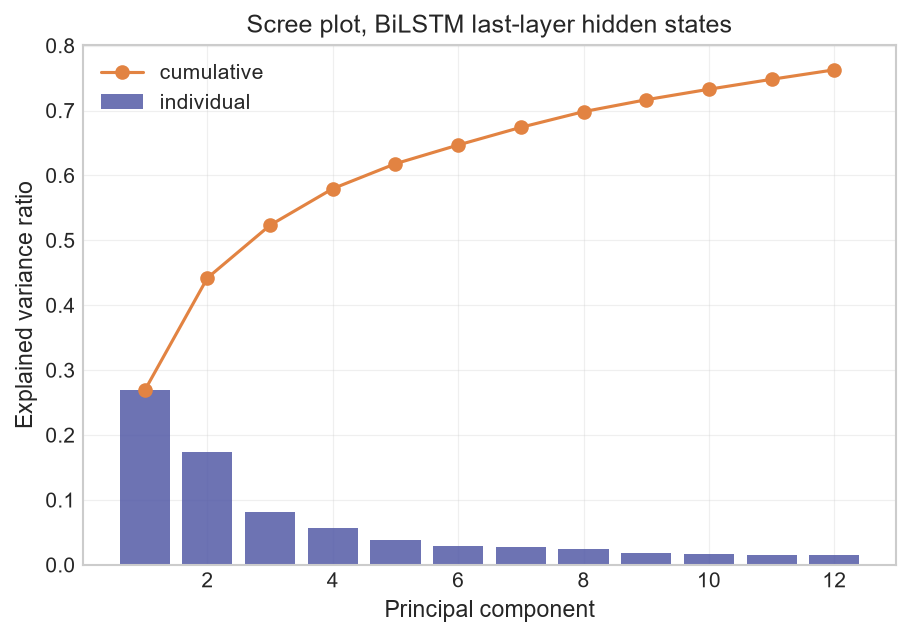

Explained variance (first 2): [0.26899999380111694, 0.17299999296665192] | cumulative 4 PC: 0.58


In [12]:
from sklearn.decomposition import PCA

n_days, T, two_h = hidden_all.shape
H      = hidden_all.reshape(-1, two_h)
y_pred = preds_all.reshape(-1)
pr     = probs_all.reshape(-1, NUM_CLASSES)

minute_idx = np.tile(np.arange(T), n_days)
day_idx    = np.repeat(np.arange(n_days), T)
arch_arr   = np.array([a for a, _, _ in all_days])
date_arr   = np.array([str(d) for _, d, _ in all_days])
arch_per_min = arch_arr[day_idx]
date_per_min = date_arr[day_idx]
susp_per_min = inference_df["suspicious_nocturnal"].to_numpy()

rng = np.random.default_rng(42)
n_total  = H.shape[0]
sample_n = min(50_000, n_total)
sel  = rng.choice(n_total, size=sample_n, replace=False)
Hs   = H[sel]
yp   = y_pred[sel]
prs  = pr[sel]
susp = susp_per_min[sel]
arch_s = arch_per_min[sel]
date_s = date_per_min[sel]
mins_s = minute_idx[sel]

print(f"Total minutes: {n_total:,} | sampled: {sample_n:,} (seed 42)")

# Scree: 12 components to see where the curve flattens
pca_scree = PCA(n_components=12, random_state=42).fit(Hs)
evr = pca_scree.explained_variance_ratio_
pd.DataFrame({"component": np.arange(1, 13),
              "explained_variance_ratio": evr,
              "cumulative": np.cumsum(evr)}).to_csv("supplementary5_pca_variance.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(np.arange(1, 13), evr, color=LABEL_COLORS["Off"], alpha=0.85, label="individual")
ax.plot(np.arange(1, 13), np.cumsum(evr), marker="o", color=LABEL_COLORS["On"], label="cumulative")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("Scree plot, BiLSTM last-layer hidden states")
ax.legend()
fig.savefig(FIG_DIR / "pca_scree.png")
plt.show()
print("Explained variance (first 2):", evr[:2].round(3).tolist(),
      "| cumulative 4 PC:", round(float(np.cumsum(evr)[3]), 3))

In [13]:
# 2-component projection used by all latent-space figures below
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(Hs)
print("PCA explained variance (PC1, PC2):", pca.explained_variance_ratio_.round(3).tolist())
print("Z shape:", Z.shape)

PCA explained variance (PC1, PC2): [0.26899999380111694, 0.17299999296665192]
Z shape: (50000, 2)


The two-dimensional projection, coloured by the class the model predicted for each minute, is
the central figure of this notebook. If the hidden layer has learned the behavioural structure,
the three classes should occupy distinguishable regions without the classification head being
involved in the projection at all. The reading, in short: the second component separates On
minutes (negative side) from Off and Nocturnal, and the first component separates Nocturnal
(negative side) from Off. The interfaces between regions are fuzzy rather than sharp, which is
what one expects at behavioural transitions: the boundary minutes are the arrivals and departures
where the thermal signal genuinely mixes two states.

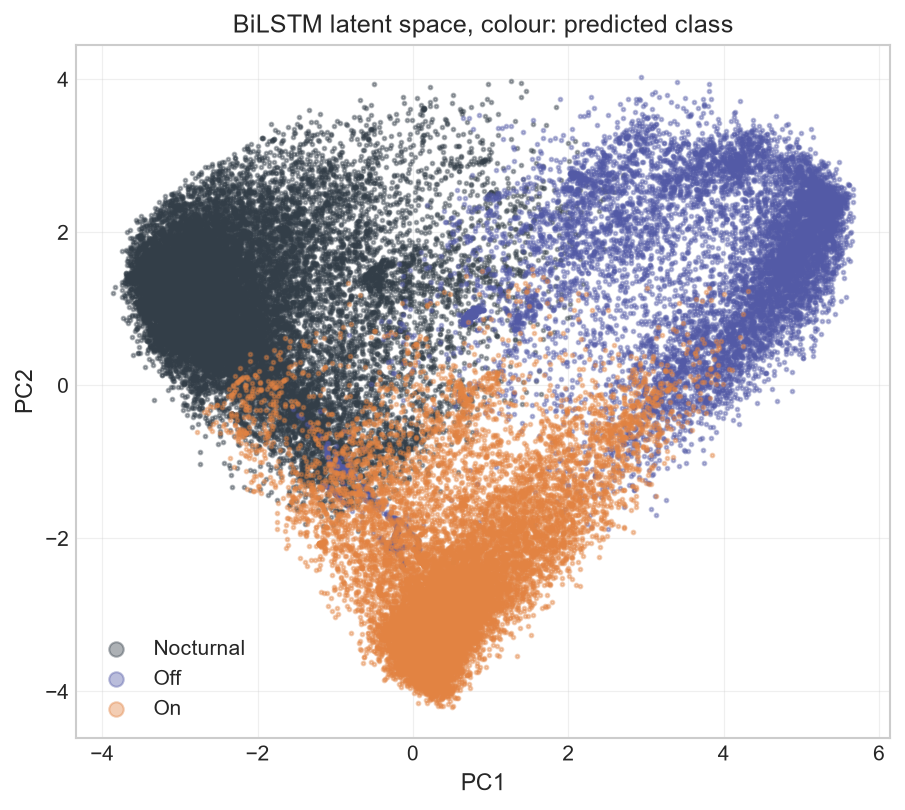

Nocturnal : n= 22664 | PC1 mean=-2.09 | PC2 mean=+1.04
Off       : n= 10974 | PC1 mean=+3.56 | PC2 mean=+1.50
On        : n= 16362 | PC1 mean=+0.50 | PC2 mean=-2.44


In [14]:
fig, ax = plt.subplots(figsize=(7, 6))
for c in [0, 1, 2]:
    m = yp == c
    ax.scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.4, c=COLORS[c], label=LABELS[c])
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("BiLSTM latent space, colour: predicted class")
ax.legend(markerscale=4, loc="lower left")
fig.savefig(FIG_DIR / "latent_space_pca_by_predicted_label.png")
plt.show()

for c in [0, 1, 2]:
    m = yp == c
    print(f"{LABELS[c]:10s}: n={m.sum():6d} | PC1 mean={Z[m,0].mean():+.2f} | PC2 mean={Z[m,1].mean():+.2f}")

The same projection with the suspicious Nocturnal minutes highlighted answers a narrower
question: do the flagged events live where the model's On region is? The flagged minutes are
drawn over the full sample in grey. If the flag is meaningful, the highlighted points should
sit closer to the On territory than a random Nocturnal minute would, which is the latent-space
counterpart of the rule-based correction that S4 applies at the event level.

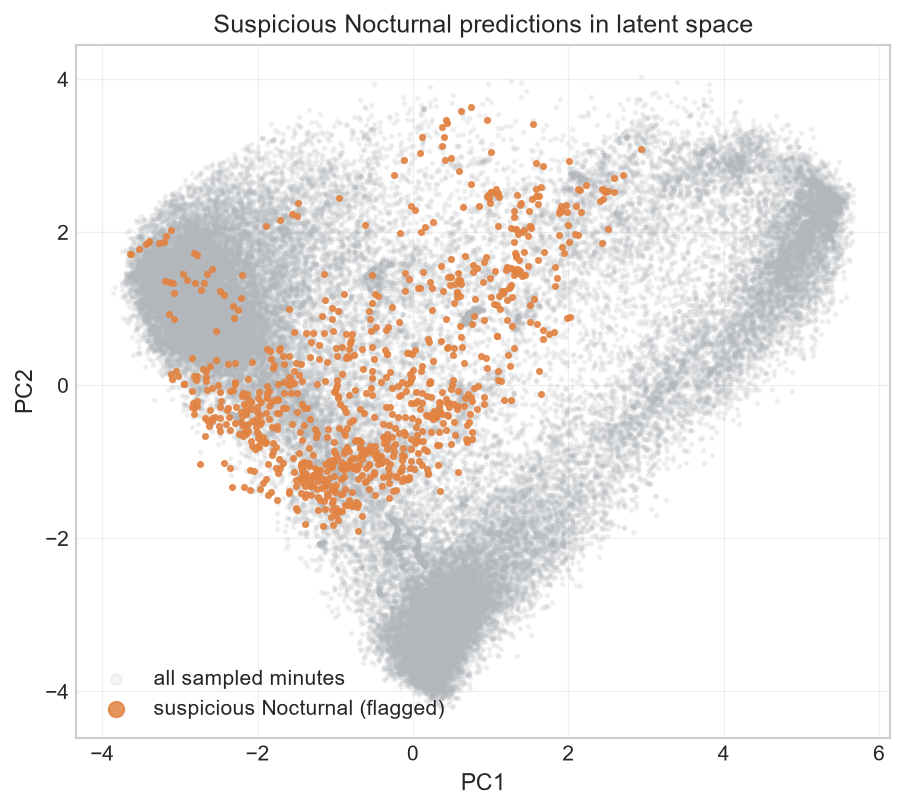

Flagged minutes in sample: 850 of 50,000 (1.70%)
Flagged   : PC1 mean=-0.55, PC2 mean=+0.11
Other Nocturnal minutes: PC1 mean=-2.15, PC2 mean=+1.08


In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(Z[:, 0], Z[:, 1], s=3, alpha=0.15, c=DIAG_COLOR, label="all sampled minutes")
m = susp.astype(bool)
ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.85, c=COLORS[2], label="suspicious Nocturnal (flagged)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Suspicious Nocturnal predictions in latent space")
ax.legend(markerscale=3, loc="lower left")
fig.savefig(FIG_DIR / "suspicious_nocturnal_latent_space.png")
plt.show()
print(f"Flagged minutes in sample: {m.sum():,} of {sample_n:,} ({100.0*m.mean():.2f}%)")
if m.sum() > 0:
    print(f"Flagged   : PC1 mean={Z[m,0].mean():+.2f}, PC2 mean={Z[m,1].mean():+.2f}")
    mn = (yp == 0) & (~m)
    print(f"Other Nocturnal minutes: PC1 mean={Z[mn,0].mean():+.2f}, PC2 mean={Z[mn,1].mean():+.2f}")

In [16]:
# The seeded sample is exported for reuse (misma estructura que la tabla de S4, con nombres propios de S5)
latent_sample = pd.DataFrame({
    "PC1": Z[:, 0], "PC2": Z[:, 1],
    "archivo": arch_s, "date": date_s, "minute_of_day": mins_s,
    "prediccion": yp, "prediccion_label": [LABEL_MAP[int(v)] for v in yp],
    "prob_nocturnal": prs[:, 0], "prob_off": prs[:, 1], "prob_on": prs[:, 2],
    "suspicious_nocturnal": susp,
})
latent_sample.to_csv("supplementary5_hidden_state_sample.csv", index=False)
print("Latent sample saved:", latent_sample.shape, "-> supplementary5_hidden_state_sample.csv")

Latent sample saved: (50000, 11) -> supplementary5_hidden_state_sample.csv


## G. Mean activation profiles of the 128 hidden units

Each of the 128 last-layer units (64 forward, 64 backward) has a mean activation across all
minutes of each predicted class, plus a fourth column for the suspicious Nocturnal minutes.
The result is a 128 x 4 profile matrix. Units are grouped by their dominant condition, the
condition where the absolute mean activation is largest, and within each group they are ordered
by signed strength. The ordering is deterministic, no clustering is applied anywhere in this
notebook, so the same figure comes out of every run.

A caution about language: these units are *correlated with* the predicted classes, they are not
little decision makers for On, Off, or Nocturnal. The honest reading is that the layer contains
subpopulations whose activity tracks each condition, which is exactly what a representation that
has learned the behavioural structure should look like.

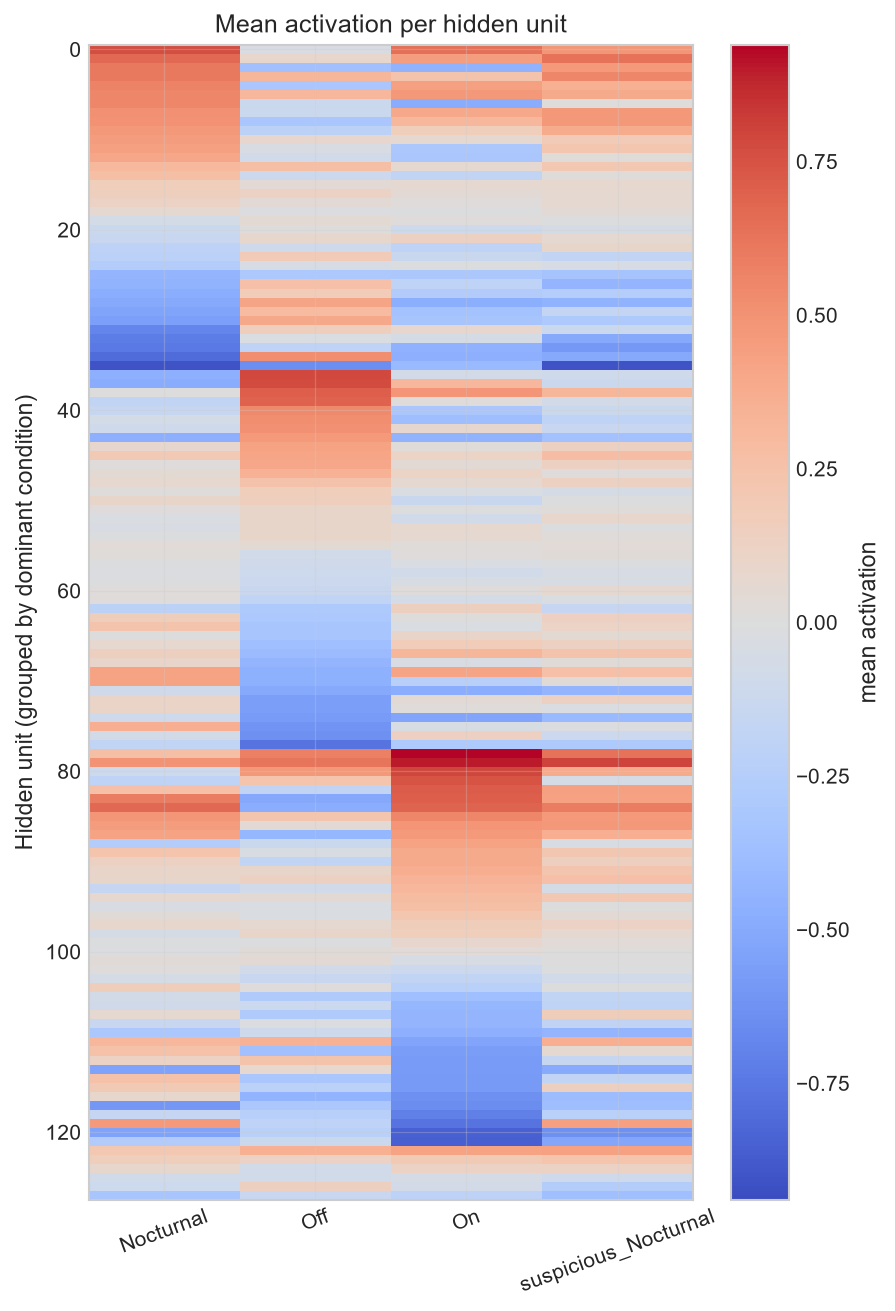

Heatmap rows: 128 | symmetric colour limits: +- 0.94


In [17]:
hidden_dim = H.shape[1]
profiles = np.zeros((hidden_dim, 4))
for c in [0, 1, 2]:
    m = y_pred == c
    if m.any():
        profiles[:, c] = H[m].mean(axis=0)
m_susp = susp_per_min.astype(bool)
if m_susp.any():
    profiles[:, 3] = H[m_susp].mean(axis=0)

cond_cols = ["Nocturnal", "Off", "On", "suspicious_Nocturnal"]

# Deterministic row ordering: dominant condition first, signed strength second (orden determinista)
abs_profiles = np.abs(profiles)
dominant = abs_profiles.argmax(axis=1)
signed_strength = profiles[np.arange(hidden_dim), dominant]
order = np.lexsort((-signed_strength, dominant))

lim = max(abs(profiles.min()), abs(profiles.max()))
fig, ax = plt.subplots(figsize=(6.5, 10))
im = ax.imshow(profiles[order], aspect="auto", cmap=HEAT_CMAP, vmin=-lim, vmax=lim)
ax.set_xticks(range(4))
ax.set_xticklabels(cond_cols, rotation=20)
ax.set_yticks(range(0, hidden_dim, 20))
ax.set_yticklabels(range(0, hidden_dim, 20))
ax.set_ylabel("Hidden unit (grouped by dominant condition)")
ax.set_title("Mean activation per hidden unit")
fig.colorbar(im, ax=ax, label="mean activation")
fig.savefig(FIG_DIR / "hidden_unit_activation_heatmap.png")
plt.show()
print("Heatmap rows:", hidden_dim, "| symmetric colour limits: +-", round(lim, 3))

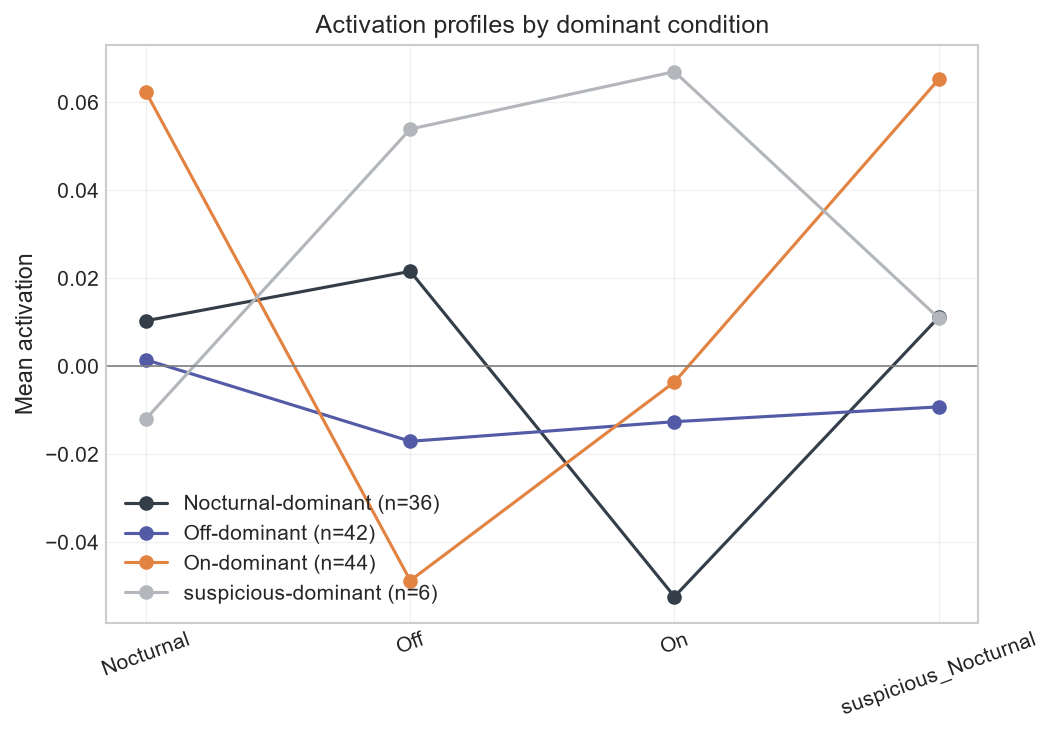

In [18]:
# Mean profile per dominant-condition group: the block structure of the heatmap, in one line plot
fig, ax = plt.subplots(figsize=(7.5, 5))
group_style = {0: ("Nocturnal-dominant", LABEL_COLORS["Nocturnal"]),
               1: ("Off-dominant", LABEL_COLORS["Off"]),
               2: ("On-dominant", LABEL_COLORS["On"]),
               3: ("suspicious-dominant", DIAG_COLOR)}
for gval, (gname, gcolor) in group_style.items():
    members = profiles[dominant == gval]
    if len(members) == 0:
        continue
    ax.plot(range(4), members.mean(axis=0), marker="o", color=gcolor,
            label=f"{gname} (n={len(members)})")
ax.set_xticks(range(4))
ax.set_xticklabels(cond_cols, rotation=20)
ax.set_ylabel("Mean activation")
ax.set_title("Activation profiles by dominant condition")
ax.axhline(0, color="grey", linewidth=0.8)
ax.legend()
fig.savefig(FIG_DIR / "activation_profiles_by_dominant_condition.png")
plt.show()

## H. How selective is each unit

A descriptive summary per unit: the dominant condition, the mean activation on it, and a
selectivity index defined as the absolute mean activation on the dominant condition minus the
mean absolute activation on the other three. Units with a high index fire for one condition and
stay quiet for the rest; units near zero carry little class-conditional information on average
(they may still encode within-day dynamics that this per-condition mean washes out, so a low
index is not the same as a useless unit). The distributions below summarise the layer without
assigning units to groups.

In [19]:
abs_p = np.abs(profiles)
dominant_name = np.array([cond_cols[d] for d in dominant])
strength = profiles[np.arange(hidden_dim), dominant]
others_mean_abs = (abs_p.sum(axis=1) - abs_p[np.arange(hidden_dim), dominant]) / 3.0
selectivity = abs_p[np.arange(hidden_dim), dominant] - others_mean_abs

unit_df = pd.DataFrame({
    "unit_index": np.arange(hidden_dim),
    "mean_nocturnal": profiles[:, 0], "mean_off": profiles[:, 1],
    "mean_on": profiles[:, 2], "mean_suspicious_nocturnal": profiles[:, 3],
    "dominant_condition": dominant_name,
    "dominant_activation": strength,
    "selectivity_index": selectivity,
})
unit_df.to_csv("supplementary5_hidden_unit_profiles.csv", index=False)
print("Unit profiles saved:", unit_df.shape, "-> supplementary5_hidden_unit_profiles.csv")
print(unit_df["dominant_condition"].value_counts().to_string())

Unit profiles saved: (128, 8) -> supplementary5_hidden_unit_profiles.csv
dominant_condition
On                      44
Off                     42
Nocturnal               36
suspicious_Nocturnal     6


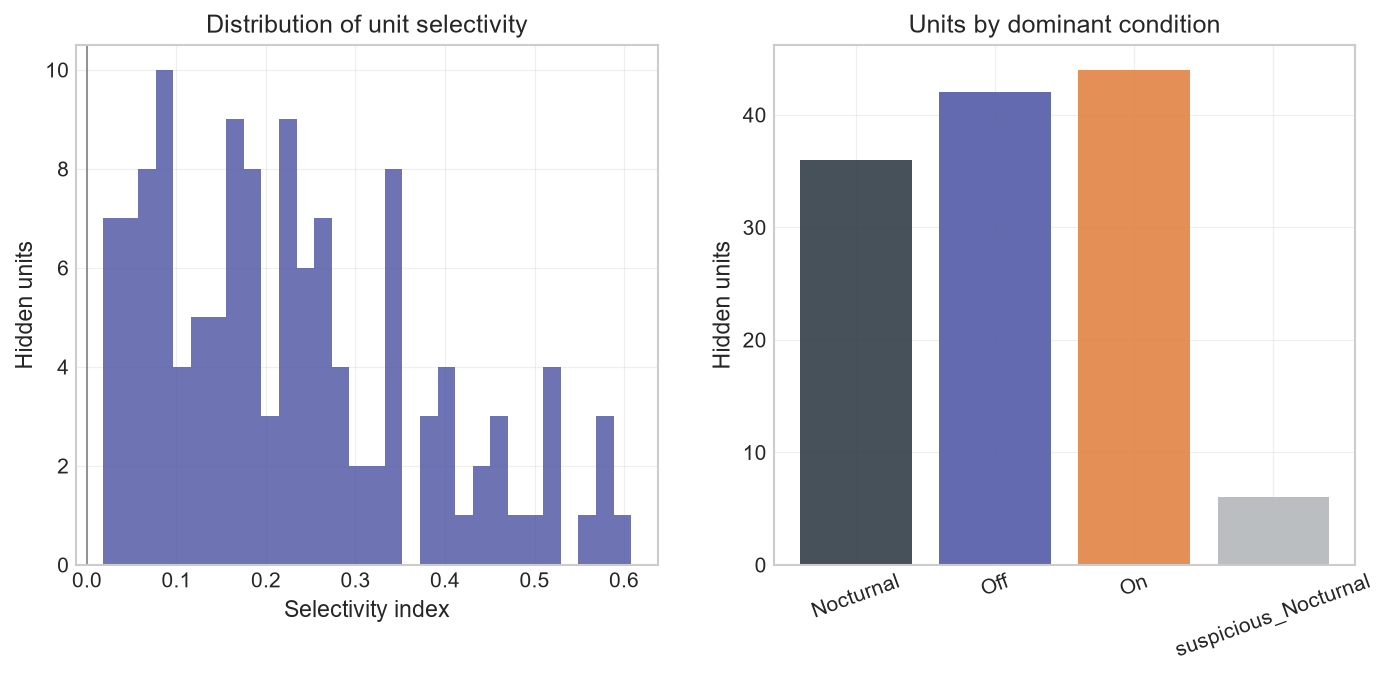

Units with selectivity index > 0.1 : 96 / 128
Units with max |mean activation| < 0.05 (near-inactive on averages): 2 / 128


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(selectivity, bins=30, color=LABEL_COLORS["Off"], alpha=0.85)
axes[0].axvline(0, color="grey", linewidth=0.8)
axes[0].set_xlabel("Selectivity index")
axes[0].set_ylabel("Hidden units")
axes[0].set_title("Distribution of unit selectivity")

counts = unit_df["dominant_condition"].value_counts().reindex(cond_cols).fillna(0)
bar_colors = [LABEL_COLORS["Nocturnal"], LABEL_COLORS["Off"], LABEL_COLORS["On"], DIAG_COLOR]
axes[1].bar(range(4), counts.values, color=bar_colors, alpha=0.9)
axes[1].set_xticks(range(4))
axes[1].set_xticklabels(cond_cols, rotation=20)
axes[1].set_ylabel("Hidden units")
axes[1].set_title("Units by dominant condition")

fig.savefig(FIG_DIR / "unit_selectivity_distributions.png")
plt.show()

n_selective = int((selectivity > 0.1).sum())
n_weak = int((np.abs(profiles).max(axis=1) < 0.05).sum())
print(f"Units with selectivity index > 0.1 : {n_selective} / {hidden_dim}")
print(f"Units with max |mean activation| < 0.05 (near-inactive on averages): {n_weak} / {hidden_dim}")

## I. Quality checks

A short closing check that the exported artefacts exist, are non-empty, and agree with each
other on the basic counts. Nothing here modifies the S4 outputs.

In [21]:
expected_files = [
    "supplementary5_day_blocking_QA.csv",
    "resultados_supplementary5_inference_raw.csv",
    "eventos_supplementary5_diagnostics.csv",
    "supplementary5_hidden_state_sample.csv",
    "supplementary5_hidden_unit_profiles.csv",
    "supplementary5_pca_variance.csv",
    FIG_DIR / "pca_scree.png",
    FIG_DIR / "latent_space_pca_by_predicted_label.png",
    FIG_DIR / "suspicious_nocturnal_latent_space.png",
    FIG_DIR / "hidden_unit_activation_heatmap.png",
    FIG_DIR / "activation_profiles_by_dominant_condition.png",
    FIG_DIR / "unit_selectivity_distributions.png",
]
missing = []
for f in expected_files:
    p = Path(f)
    ok = p.exists() and p.stat().st_size > 0
    print(("OK  " if ok else "MISS"), f, (f"{p.stat().st_size:,} bytes" if p.exists() else ""))
    if not ok:
        missing.append(str(f))
if missing:
    raise RuntimeError(f"Missing or empty outputs: {missing}")

assert hidden_all.shape[2] == 2 * HIDDEN_SIZE == 128
assert set(np.unique(y_pred)).issubset({0, 1, 2})
print()
print("Days:", len(all_days), "| minutes:", n_total, "| sample:", sample_n,
      "| flagged minutes (full):", int(susp_per_min.sum()))
print("All S5 outputs verified.")

OK   supplementary5_day_blocking_QA.csv 39,467 bytes
OK   resultados_supplementary5_inference_raw.csv 58,172,359 bytes
OK   eventos_supplementary5_diagnostics.csv 1,381,886 bytes
OK   supplementary5_hidden_state_sample.csv 6,541,962 bytes
OK   supplementary5_hidden_unit_profiles.csv 16,846 bytes
OK   supplementary5_pca_variance.csv 355 bytes
OK   figures\supplementary5\pca_scree.png 95,026 bytes
OK   figures\supplementary5\latent_space_pca_by_predicted_label.png 1,597,234 bytes
OK   figures\supplementary5\suspicious_nocturnal_latent_space.png 1,512,118 bytes
OK   figures\supplementary5\hidden_unit_activation_heatmap.png 132,310 bytes
OK   figures\supplementary5\activation_profiles_by_dominant_condition.png 229,177 bytes
OK   figures\supplementary5\unit_selectivity_distributions.png 91,307 bytes

Days: 286 | minutes: 411840 | sample: 50000 | flagged minutes (full): 7419
All S5 outputs verified.


## Glossary / Glosario

| Term | English | Espanol |
|------|---------|---------|
| Hidden state | The 128 values the last LSTM layer produces for each minute; the model's internal summary of that minute | Los 128 valores que la ultima capa LSTM produce por minuto; el resumen interno del modelo para ese minuto |
| Latent space | The space formed by those internal vectors, where similar minutes sit close together | El espacio formado por esos vectores internos, donde minutos similares quedan cerca |
| PCA | Principal Component Analysis; a projection that keeps the directions of most variance | Analisis de Componentes Principales; proyeccion que conserva las direcciones de mayor varianza |
| Scree plot | Bar plot of explained variance per component, used to decide how many components matter | Grafico de barras de varianza explicada por componente, para decidir cuantos componentes importan |
| Explained variance ratio | Fraction of the total variance carried by one component | Fraccion de la varianza total que lleva un componente |
| Hidden unit | One of the 128 coordinates of the last hidden layer (64 forward + 64 backward directions) | Una de las 128 coordenadas de la ultima capa oculta (64 direcciones hacia adelante + 64 hacia atras) |
| Dominant condition | The column (Nocturnal, Off, On, suspicious Nocturnal) where a unit's absolute mean activation is largest | La columna donde la activacion media absoluta de una unidad es mayor |
| Selectivity index | Absolute mean activation on the dominant condition minus the mean absolute activation on the other three | Activacion media absoluta en la condicion dominante menos la media absoluta de las otras tres |
| Suspicious Nocturnal | Diagnostic flag from S4 for short or daytime Nocturnal events that may hide a real On bout | Bandera diagnostica de S4 para eventos Nocturnal cortos o diurnos que pueden esconder un On real |
| Out-of-sample | Species and recordings that contributed nothing to training, validation, or cross-validation | Especies y grabaciones que no aportaron nada al entrenamiento, validacion o validacion cruzada |
| On-bout / Off-bout | Period with the bird incubating on the nest / away from the nest | Periodo con el ave incubando en el nido / fuera del nido |
| Nocturnal | Night-time block where incubation is continuous and bouts are not separated | Bloque nocturno donde la incubacion es continua y no se separan bouts |